# SP-004 — Filler

Filler agota la fuente activa buscando piezas pendientes viables. Se compara con FF, BF y WF en SMALL, MEDIUM y COMPLEX; FF ya ordena por área.

Configuración TA-027: raster 1 mm, giros 5°; SMALL margen/separación 0/0 mm y MEDIUM/COMPLEX 1/1 mm. Prioridad retazo → plancha.

## Preparación del entorno

In [1]:
# Importamos Path para buscar archivos del repositorio de forma portable.
from pathlib import Path
# Importamos sys para que Python encuentre backend y experimentos.
import sys
# Tomamos la carpeta de trabajo como raíz candidata del repositorio.
repo_root = Path.cwd()
# Comprobamos que Colab esté ubicado dentro de una copia del repositorio.
if not (repo_root / "experiments/optimization/loader.py").exists():
    # Usamos la ruta convencional si el repositorio fue clonado en Colab.
    repo_root = Path("/content/NewGlass")
# Evitamos continuar con un path que no tiene los fixtures.
if not (repo_root / "experiments/optimization/loader.py").exists():
    # Explicamos cómo preparar el entorno.
    raise RuntimeError("Clona NewGlass en /content/NewGlass o ejecuta el notebook desde la raíz del repositorio.")
# Permitimos imports del paquete app usado por el motor.
sys.path.insert(0, str(repo_root / "backend"))
# Permitimos importar el loader experimental versionado.
sys.path.insert(0, str(repo_root))
# Confirmamos la ubicación real del código.
print(f"Repositorio: {repo_root}")
# Confirmamos la política de recursos del Spike.
print("Ejecución: secuencial; una corrida a la vez")

Repositorio: C:\Users\patri\GitHub\optimizador-vidrio
Ejecución: secuencial; una corrida a la vez


**Interpretación:** La ruta detectada debe contener el loader experimental; no se altera ningún archivo productivo.

## Validar fixtures

Ejecuta el paso experimental y muestra su salida guardada.

In [2]:
# Reutilizamos el loader y la lista cerrada de casos.
from experiments.optimization.loader import CASES, read_case
# Creamos el resumen que usaremos en las explicaciones posteriores.
fixture_summary = {}
# Recorremos SMALL, MEDIUM y COMPLEX en orden fijo.
for case_id in CASES:
    # Leemos una copia de solo lectura del JSON congelado.
    data = read_case(case_id)
    # Conservamos conteos y configuración.
    fixture_summary[case_id] = {"pieces": len(data["pieces"]), "stock": len(data["stock"]), "config": data["config"]}
    # Mostramos la evidencia cargada directamente del fixture.
    print(case_id, fixture_summary[case_id])

EXP-SMALL-001 {'pieces': 1, 'stock': 2, 'config': {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 0, 'separation_mm': 0}}
EXP-MEDIUM-001 {'pieces': 3, 'stock': 3, 'config': {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}}
EXP-COMPLEX-001 {'pieces': 6, 'stock': 5, 'config': {'resolution_mm': 1, 'angular_step_deg': 5, 'margin_mm': 1, 'separation_mm': 1}}


**Interpretación:** Se muestran los conteos de filas de piezas y stock antes de expandir cantidades; el loader conserva validaciones del repositorio.

## Carga SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [3]:
# Reutilizamos la construcción oficial de snapshots.
from experiments.optimization.loader import load_problem
# Leemos configuración y límites de residuos de SMALL.
small_data = read_case("EXP-SMALL-001")
# Construimos el problema sin base de datos ni mutación del fixture.
small_problem = load_problem("EXP-SMALL-001")
# Contamos piezas físicas solicitadas.
print("unidades expandidas:", len(small_problem.units))
# Mostramos cuántas combinaciones material-espesor se procesan.
print("grupos de material:", len(small_problem.groups))

unidades expandidas: 3
grupos de material: 1


**Interpretación:** SMALL tiene una sola geometría de pieza; el loader expande la cantidad solicitada y mantiene ambos tipos de stock.

## Carga MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [4]:
# Conservamos el fixture original y sus límites de residuo.
medium_data = read_case("EXP-MEDIUM-001")
# Construimos snapshots y candidatos compatibles.
medium_problem = load_problem("EXP-MEDIUM-001")
# Contamos cada unidad individual del pedido.
print("unidades expandidas:", len(medium_problem.units))
# Contamos retazos y planchas compatibles.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in medium_problem.groups))

unidades expandidas: 9
fuentes físicas: 4


**Interpretación:** El loader agrupa por material y espesor, por lo que el conteo de fuentes no mezcla materiales incompatibles.

## Carga COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [5]:
# Leemos el fixture complejo congelado sin editarlo.
complex_data = read_case("EXP-COMPLEX-001")
# Reconstruimos las unidades y el stock compatible.
complex_problem = load_problem("EXP-COMPLEX-001")
# Mostramos la carga real de piezas.
print("unidades expandidas:", len(complex_problem.units))
# Confirmamos separación por compatibilidad.
print("grupos material-espesor:", len(complex_problem.groups))
# Contamos stock por grupo.
print("fuentes físicas:", sum(len(group.stock_candidates) for group in complex_problem.groups))

unidades expandidas: 24
grupos material-espesor: 2
fuentes físicas: 7


**Interpretación:** COMPLEX contiene varios grupos; cada grupo conserva su inventario compatible por separado.

## Orden original

Ejecuta el paso experimental y muestra su salida guardada.

In [6]:
# Recorremos cada fixture sin reescribir sus filas.
for case_id in CASES:
    # Abrimos la representación original del caso.
    data = read_case(case_id)
    # Mostramos IDs, cantidades y tipos de geometría.
    print(case_id, [(row["id_pieza"], row["cantidad"], row["geometria"]["type"]) for row in data["pieces"]])

EXP-SMALL-001 [(1, 3, 'RECTANGULO')]
EXP-MEDIUM-001 [(1, 3, 'RECTANGULO'), (2, 4, 'RECTANGULO'), (3, 2, 'CIRCUNFERENCIA')]
EXP-COMPLEX-001 [(1, 5, 'RECTANGULO'), (2, 6, 'RECTANGULO'), (3, 4, 'CIRCUNFERENCIA'), (4, 4, 'POLIGONO_CONVEXO'), (5, 3, 'RECTANGULO'), (6, 2, 'POLIGONO_CONVEXO')]


**Interpretación:** El orden de entrada queda visible para distinguirlo del orden de selección calculado por área.

## Orden ANTES versus FILLER

Ejecuta el paso experimental y muestra su salida guardada.

In [7]:
# Guardamos el orden original de las filas.
before_order = [(row["id_pieza"], row["cantidad"]) for row in medium_data["pieces"]]
# Aplicamos los desempates deterministas de Filler.
filler_order = sorted(medium_problem.units, key=lambda unit: (-unit.area_mm2, unit.piece_id, unit.unit_index, unit.order_id))
# Mostramos el orden del fixture.
print("ANTES:", before_order)
# Mostramos unidades expandidas en orden decreciente.
print("FILLER:", [(unit.piece_id, unit.unit_index, str(unit.area_mm2)) for unit in filler_order])

ANTES: [(1, 3), (2, 4), (3, 2)]
FILLER: [(1, 1, '18.00'), (1, 2, '18.00'), (1, 3, '18.00'), (3, 1, '12.57'), (3, 2, '12.57'), (2, 1, '6.00'), (2, 2, '6.00'), (2, 3, '6.00'), (2, 4, '6.00')]


**Interpretación:** La lista posterior incluye cantidad expandida; el ID estable resuelve empates de área.

## Implementación experimental

Ejecuta el paso experimental y muestra su salida guardada.

In [8]:
# Importamos inspect para mostrar de qué módulo viene la política experimental.
import inspect
# Importamos únicamente el optimizador aislado de SP-004.
from experiments.optimization.filler import FillerExperimental
# Verificamos la ruta experimental del código.
print("módulo:", inspect.getmodule(FillerExperimental).__file__)
# Resumimos la regla central del recorrido.
print("decisión central:", "buscar la primera pieza pendiente factible en la fuente activa")
# Mostramos el método real para que Andro pueda seguir sus pasos y comentarios.
print(inspect.getsource(FillerExperimental.optimize))

módulo: C:\Users\patri\GitHub\optimizador-vidrio\experiments\optimization\filler\filler_experimental.py
decisión central: buscar la primera pieza pendiente factible en la fuente activa
    def optimize(self, problem: OptimizationProblem, *, checkpoint=None,
                 minimum_width_mm=Decimal(1), minimum_height_mm=Decimal(1)):
        """Retorna resultado medido con métricas oficiales y una traza diagnóstica."""
        started = perf_counter_ns()
        checkpoint = checkpoint or (lambda: None)
        groups = tuple(replace(
            group,
            units=tuple(sorted(group.units, key=lambda unit: (
                -unit.area_mm2, unit.piece_id, unit.unit_index, unit.order_id,
            ))),
            stock_candidates=tuple(sorted(
                group.stock_candidates,
                key=lambda stock: (stock.source is MaterialSource.SHEET,
                                   stock.material_id, stock.physical_unit_index),
            )),
        ) for group in sorte

**Interpretación:** El algoritmo reutiliza candidatos factibles, raster, rotaciones, layout, colisiones y métricas existentes; la salida imprime el método experimental que toma las decisiones y permite inspeccionarlo línea por línea.

## Demo didáctica — NO PERTENECE AL BENCHMARK OFICIAL

Ejecuta el paso experimental y muestra su salida guardada.

In [9]:
# Definimos una capacidad abstracta solo para ilustrar la política.
demo_capacity = 2
# Definimos piezas didácticas ordenadas por tamaño.
demo_pending = [("grande", 5), ("pequena-A", 2), ("pequena-B", 1)]
# Inicializamos las piezas que entran en la fuente ficticia.
demo_placed = []
# Guardamos el espacio abstracto disponible.
demo_remaining = demo_capacity
# Probamos cada pieza restante en orden didáctico.
for name, size in demo_pending:
    # Comprobamos cabida mediante capacidad abstracta, no geometría.
    fits = size <= demo_remaining
    # Hacemos visible el rechazo temporal o aceptación.
    print(name, "entra" if fits else "no entra")
    # Solo las piezas factibles consumen capacidad.
    if fits:
        # Registramos la pieza aceptada.
        demo_placed.append(name)
        # Reducimos la capacidad restante.
        demo_remaining -= size
# Confirmamos que se agotó la fuente antes de cambiar.
print("misma fuente activa; colocadas:", demo_placed)

grande no entra
pequena-A entra
pequena-B no entra
misma fuente activa; colocadas: ['pequena-A']


**Interpretación:** La demostración es una analogía escalar; el benchmark real decide factibilidad con la geometría rasterizada de NewGlass.

## Ejecutar Filler SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [10]:
# Ejecutamos Filler y respetamos límites oficiales.
small_filler, small_trace = FillerExperimental().optimize(small_problem, minimum_width_mm=__import__("decimal").Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), minimum_height_mm=__import__("decimal").Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))
# Recorremos intentos en su orden real.
for attempt in small_trace.attempts:
    # Mostramos factibilidad, fuente, posición y rotación.
    print(attempt)
# Resumimos decisiones diagnósticas.
print("cambios de fuente:", small_trace.source_switches, "saltos:", small_trace.skipped_piece_attempts)

{'piece_id': 1, 'unit_index': 1, 'area_mm2': '4.00', 'source': 'RETAZO', 'material_id': 1, 'physical_unit_index': 1, 'fits': True, 'rotation_deg': '0', 'x_mm': '0', 'y_mm': '0', 'decision': 'place'}
{'piece_id': 1, 'unit_index': 2, 'area_mm2': '4.00', 'source': 'RETAZO', 'material_id': 1, 'physical_unit_index': 1, 'fits': False, 'rotation_deg': None, 'x_mm': None, 'y_mm': None, 'decision': 'skip_temporarily'}
{'piece_id': 1, 'unit_index': 3, 'area_mm2': '4.00', 'source': 'RETAZO', 'material_id': 1, 'physical_unit_index': 1, 'fits': False, 'rotation_deg': None, 'x_mm': None, 'y_mm': None, 'decision': 'skip_temporarily'}
{'piece_id': 1, 'unit_index': 2, 'area_mm2': '4.00', 'source': 'PLANCHA', 'material_id': 2, 'physical_unit_index': 1, 'fits': True, 'rotation_deg': '0', 'x_mm': '0', 'y_mm': '0', 'decision': 'place'}
{'piece_id': 1, 'unit_index': 3, 'area_mm2': '4.00', 'source': 'PLANCHA', 'material_id': 2, 'physical_unit_index': 1, 'fits': True, 'rotation_deg': '0', 'x_mm': '2', 'y_mm':

**Interpretación:** La traza muestra la progresión real sobre el retazo y la plancha de SMALL.

## Visualización SMALL

Ejecuta el paso experimental y muestra su salida guardada.

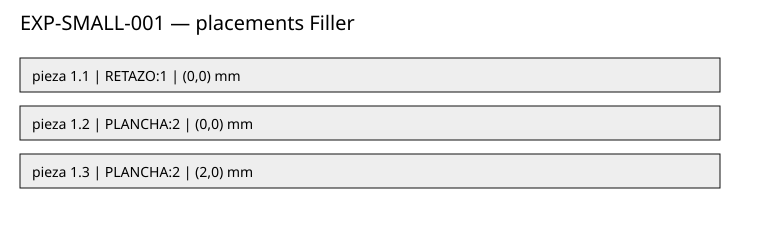

In [11]:
# Definimos un generador SVG pequeño sin dependencias gráficas externas.
def placement_svg(result, title):
    # Iniciamos el lienzo blanco.
    rows = [f'<svg xmlns="http://www.w3.org/2000/svg" width="760" height="{100 + 48 * len(result.placements)}" viewBox="0 0 760 {100 + 48 * len(result.placements)}">']
    # Garantizamos fondo blanco.
    rows.append('<rect width="100%" height="100%" fill="white"/>')
    # Añadimos el título descriptivo.
    rows.append(f'<text x="20" y="30" font-family="sans-serif" font-size="20">{title}</text>')
    # Dibujamos una fila por pieza realmente colocada.
    for index, placement in enumerate(result.placements):
        # Separamos visualmente las filas.
        y = 58 + index * 48
        # Resumimos la identidad y coordenadas.
        label = f"pieza {placement.piece.piece_id}.{placement.piece.unit_index} | {placement.stock.source.value}:{placement.stock.material_id} | ({placement.x_mm},{placement.y_mm}) mm"
        # Trazamos una barra monocroma por placement.
        rows.append(f'<rect x="20" y="{y}" width="700" height="34" fill="#eeeeee" stroke="#111111"/>')
        # Etiquetamos el placement.
        rows.append(f'<text x="32" y="{y + 23}" font-family="sans-serif" font-size="14">{label}</text>')
    # Cerramos el SVG.
    rows.append('</svg>')
    # Devolvemos el gráfico como imagen vectorial.
    return "".join(rows)
# Generamos la figura del caso pequeño.
small_svg = placement_svg(small_filler, "EXP-SMALL-001 — placements Filler")
# El notebook guarda esta salida como SVG embebido.
print(small_svg)

**Interpretación:** El gráfico representa el orden y stock de cada placement; no sustituye el detalle geométrico exacto del raster.

## Ejecutar FF SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [12]:
# Importamos un reloj monotónico para medir duración local.
from time import perf_counter
# Reutilizamos FF productivo sin modificarlo.
from app.modules.optimization.domain.first_fit import FirstFitOptimizer
# Reutilizamos el cálculo oficial de métricas.
from app.modules.optimization.domain.metrics import calculate_metrics
# Usamos Decimal para los límites explícitos del fixture.
from decimal import Decimal
# Creamos un snapshot independiente para FF.
small_ff_problem = load_problem("EXP-SMALL-001")
# Iniciamos el cronómetro antes de optimizar.
small_start = perf_counter()
# Ejecutamos la implementación productiva FF.
small_ff = FirstFitOptimizer().optimize(small_ff_problem)
# Calculamos métricas oficiales.
small_ff, _ = calculate_metrics(small_ff, Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))
# Convertimos la duración a milisegundos.
small_ff_ms = (perf_counter() - small_start) * 1000
# Mostramos avance y tiempo.
print("FF SMALL:", small_ff.placed_units, "/", small_ff.total_units, "unidades; ms:", round(small_ff_ms, 3))

FF SMALL: 3 / 3 unidades; ms: 17.622


**Interpretación:** FF coloca las tres unidades de SMALL; el tiempo se mide en esta sesión y puede variar entre equipos.

## Ejecutar BF SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [13]:
# Importamos el selector BF del motor actual.
from app.modules.optimization.domain.best_fit import BestFitOptimizer
# Preparamos una copia independiente del caso.
small_bf_problem = load_problem("EXP-SMALL-001")
# Iniciamos la medición de BF.
small_bf_start = perf_counter()
# Ejecutamos BF productivo.
small_bf = BestFitOptimizer().optimize(small_bf_problem)
# Aplicamos las métricas existentes.
small_bf, _ = calculate_metrics(small_bf, Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))
# Registramos la duración total de optimización y métricas.
small_bf_ms = (perf_counter() - small_bf_start) * 1000
# Mostramos la salida real.
print("BF SMALL:", small_bf.placed_units, "/", small_bf.total_units, "unidades; ms:", round(small_bf_ms, 3))

BF SMALL: 3 / 3 unidades; ms: 19.421


**Interpretación:** BF produce la misma cobertura en SMALL; el indicador de fuentes se compara en la tabla siguiente.

## Ejecutar WF SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [14]:
# Importamos el selector WF actual.
from app.modules.optimization.domain.worst_fit import WorstFitOptimizer
# Construimos un snapshot independiente.
small_wf_problem = load_problem("EXP-SMALL-001")
# Iniciamos la medición temporal de WF.
small_wf_start = perf_counter()
# Ejecutamos WF sin alterar su implementación.
small_wf = WorstFitOptimizer().optimize(small_wf_problem)
# Reutilizamos métricas oficiales.
small_wf, _ = calculate_metrics(small_wf, Decimal(str(small_data["residual_limits"]["minimum_width_mm"])), Decimal(str(small_data["residual_limits"]["minimum_height_mm"])))
# Guardamos el tiempo observado.
small_wf_ms = (perf_counter() - small_wf_start) * 1000
# Mostramos cobertura y tiempo.
print("WF SMALL:", small_wf.placed_units, "/", small_wf.total_units, "unidades; ms:", round(small_wf_ms, 3))

WF SMALL: 3 / 3 unidades; ms: 17.447


**Interpretación:** WF también completa SMALL; sus decisiones de fuente se ven en los placements.

## Comparar SMALL

Ejecuta el paso experimental y muestra su salida guardada.

In [15]:
# Normalizamos las columnas comparables en una fila.
def result_row(case_id, method, result, runtime_ms):
    # Obtenemos el objeto de métricas oficial del resultado.
    metrics = result.metrics
    # Contamos retazos realmente usados.
    remnants = sum(stock.source.value == "RETAZO" for stock in result.materials_used)
    # Contamos planchas realmente usadas.
    sheets = sum(stock.source.value == "PLANCHA" for stock in result.materials_used)
    # Devolvemos valores de CSV.
    return (case_id, method, result.total_units, result.placed_units, result.total_units-result.placed_units, remnants, sheets, str(metrics.utilization_pct) if metrics else "", str(metrics.waste_mm2) if metrics else "", str(metrics.recoverable_remnant_mm2) if metrics else "", round(runtime_ms,3))
# Consolidamos métodos.
small_rows = [result_row("SMALL", "FF", small_ff, small_ff_ms), result_row("SMALL", "BF", small_bf, small_bf_ms), result_row("SMALL", "WF", small_wf, small_wf_ms), result_row("SMALL", "Filler", small_filler, small_filler.computation_time_ms or 0)]
# Imprimimos encabezados.
print("case method requested placed unplaced remnants sheets utilization_pct waste recoverable_area runtime_ms")
# Recorremos filas SMALL en orden fijo.
for row in small_rows:
    # Imprimimos cada fila tabular.
    print(*row)

case method requested placed unplaced remnants sheets utilization_pct waste recoverable_area runtime_ms
SMALL FF 3 3 0 1 1 60.000 0.00 8 17.622
SMALL BF 3 3 0 1 1 60.000 0.00 8 19.421
SMALL WF 3 3 0 1 1 60.000 0.00 8 17.447
SMALL Filler 3 3 0 1 1 60.000 0.00 8 18


**Interpretación:** SMALL coincide en cobertura, fuentes y aprovechamiento; la homogeneidad explica por qué no separa las políticas.

## Ejecutar Filler MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [16]:
# Preparamos una copia nueva de MEDIUM.
medium_filler_problem = load_problem("EXP-MEDIUM-001")
# Medimos Filler con la misma regla de residuo.
medium_filler, medium_trace = FillerExperimental().optimize(medium_filler_problem, minimum_width_mm=Decimal(str(medium_data["residual_limits"]["minimum_width_mm"])), minimum_height_mm=Decimal(str(medium_data["residual_limits"]["minimum_height_mm"])))
# Mostramos cobertura.
print("unidades:", medium_filler.placed_units, "/", medium_filler.total_units)
# Mostramos unidades colocadas por fuente.
print("fuentes:", medium_trace.pieces_per_source)
# Mostramos diagnósticos de Filler.
print("skips:", medium_trace.skipped_piece_attempts, "éxitos tras skip:", medium_trace.successful_fill_after_skip)

unidades: 9 / 9
fuentes: {'RETAZO:1:1': 3, 'RETAZO:2:1': 2, 'PLANCHA:3:1': 4}
skips: 11 éxitos tras skip: 1


**Interpretación:** Filler completa 9 unidades en MEDIUM; sus fuentes y aprovechamiento coinciden con FF aunque la búsqueda puede generar intentos adicionales.

## Ejecutar FF/BF/WF MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [17]:
# Importamos el recolector explícito para soltar referencias entre corridas.
import gc
# Creamos el diccionario de resultados compactos.
medium_results = {}
# Fijamos orden secuencial de baselines.
for method_name, optimizer_class in [("FF", FirstFitOptimizer), ("BF", BestFitOptimizer), ("WF", WorstFitOptimizer)]:
    # Leemos límites oficiales sin modificar el fixture.
    case = read_case("EXP-MEDIUM-001")
    # Construimos una entrada independiente por método.
    problem = load_problem("EXP-MEDIUM-001")
    # Iniciamos la medición de la corrida.
    started = perf_counter()
    # Ejecutamos un baseline y esperamos a que termine.
    result = optimizer_class().optimize(problem)
    # Reutilizamos las métricas oficiales.
    result, _ = calculate_metrics(result, Decimal(str(case["residual_limits"]["minimum_width_mm"])), Decimal(str(case["residual_limits"]["minimum_height_mm"])))
    # Conservamos solo resultado y tiempo.
    medium_results[method_name] = (result, (perf_counter()-started)*1000)
    # Informamos resultado observado.
    print(method_name, result.placed_units, "/", result.total_units, "utilización", result.metrics.utilization_pct)
    # Liberamos referencias a geometría raster pesada.
    del problem, result
    # Solicitamos recolección antes del siguiente baseline.
    gc.collect()

FF 9 / 9 utilización 28.413
BF 9 / 9 utilización 28.413
WF 9 / 9 utilización 18.584


**Interpretación:** Los tres métodos completan MEDIUM; WF usa dos planchas, mientras FF y BF usan una.

## Comparar MEDIUM

Ejecuta el paso experimental y muestra su salida guardada.

In [18]:
# Convertimos baselines a filas comparables.
medium_rows = [result_row("MEDIUM", name, result, duration) for name, (result, duration) in medium_results.items()]
# Agregamos Filler.
medium_rows.append(result_row("MEDIUM", "Filler", medium_filler, medium_filler.computation_time_ms or 0))
# Recorremos las filas del caso.
for row in medium_rows:
    # Mostramos cada método y métrica en el mismo orden.
    print(*row)

MEDIUM FF 9 9 0 2 1 28.413 201.86 58 32.199
MEDIUM BF 9 9 0 2 1 28.413 193.86 66 43.185
MEDIUM WF 9 9 0 2 2 18.584 301.86 150 32.337
MEDIUM Filler 9 9 0 2 1 28.413 201.86 58 31


**Interpretación:** Filler y FF usan 2 retazos y 1 plancha con 28.413% de aprovechamiento. BF conserva las fuentes pero registra menos merma recuperable. WF utiliza dos planchas y baja a 18.584%.

## Ejecutar Filler COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [19]:
# Reconstruimos COMPLEX sin compartir objetos con otras corridas.
complex_filler_problem = load_problem("EXP-COMPLEX-001")
# Corremos Filler con métricas oficiales.
complex_filler, complex_trace = FillerExperimental().optimize(complex_filler_problem, minimum_width_mm=Decimal(str(complex_data["residual_limits"]["minimum_width_mm"])), minimum_height_mm=Decimal(str(complex_data["residual_limits"]["minimum_height_mm"])))
# Informamos unidades colocadas.
print("unidades:", complex_filler.placed_units, "/", complex_filler.total_units)
# Mostramos unidades asignadas a cada fuente física.
print("por fuente:", complex_trace.pieces_per_source)
# Mostramos decisiones de progresión.
print("switches:", complex_trace.source_switches, "skips:", complex_trace.skipped_piece_attempts)

unidades: 24 / 24
por fuente: {'RETAZO:1:1': 2, 'RETAZO:2:1': 2, 'PLANCHA:3:1': 9, 'PLANCHA:3:2': 6, 'RETAZO:4:1': 1, 'PLANCHA:5:1': 4}
switches: 4 skips: 49


**Interpretación:** Filler coloca las 24 unidades de COMPLEX; mantiene 3 retazos y 3 planchas.

## Ejecutar FF/BF/WF COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [20]:
# Creamos un contenedor de resultados para los baselines.
complex_results = {}
# Recorremos métodos uno a uno.
for method_name, optimizer_class in [("FF", FirstFitOptimizer), ("BF", BestFitOptimizer), ("WF", WorstFitOptimizer)]:
    # Leemos límites de residuo del fixture congelado.
    case = read_case("EXP-COMPLEX-001")
    # Creamos snapshots independientes.
    problem = load_problem("EXP-COMPLEX-001")
    # Iniciamos la medición total.
    started = perf_counter()
    # Ejecutamos el método actual.
    result = optimizer_class().optimize(problem)
    # Calculamos métricas comunes.
    result, _ = calculate_metrics(result, Decimal(str(case["residual_limits"]["minimum_width_mm"])), Decimal(str(case["residual_limits"]["minimum_height_mm"])))
    # Retenemos el resultado para la tabla.
    complex_results[method_name] = (result, (perf_counter()-started)*1000)
    # Mostramos unidades y planchas.
    print(method_name, result.placed_units, "/", result.total_units, "planchas", sum(s.source.value == "PLANCHA" for s in result.materials_used))
    # Soltamos referencias a la corrida concluida.
    del problem, result
    # Liberamos basura antes del siguiente método.
    gc.collect()

FF 24 / 24 planchas 3
BF 24 / 24 planchas 3
WF 24 / 24 planchas 4


**Interpretación:** FF y BF usan 3 planchas; WF abre una cuarta para completar el mismo pedido.

## Comparar COMPLEX

Ejecuta el paso experimental y muestra su salida guardada.

In [21]:
# Creamos filas de los baselines.
complex_rows = [result_row("COMPLEX", name, result, duration) for name, (result, duration) in complex_results.items()]
# Añadimos la fila experimental.
complex_rows.append(result_row("COMPLEX", "Filler", complex_filler, complex_filler.computation_time_ms or 0))
# Recorremos las cuatro observaciones.
for row in complex_rows:
    # Presentamos los valores comparables.
    print(*row)

COMPLEX FF 24 24 0 3 3 29.598 746.72 184 165.148
COMPLEX BF 24 24 0 3 3 29.598 746.72 184 151.328
COMPLEX WF 24 24 0 3 4 25.309 886.72 268 152.534
COMPLEX Filler 24 24 0 3 3 29.598 746.72 184 186


**Interpretación:** Las 24 unidades caben en todos los métodos. El fixture no evidencia ventaja de Filler sobre FF/BF en aprovechamiento o fuentes.

## Determinismo SMALL ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [22]:
# Creamos una firma estable sin incluir tiempo variable.
def filler_signature(case_id):
    # Reconstruimos el problema para aislar cada repetición.
    problem = load_problem(case_id)
    # Ejecutamos Filler con los límites por defecto del caso.
    result, trace = FillerExperimental().optimize(problem)
    # Recogemos decisiones reproducibles.
    signature = (tuple((p.piece.identity, p.stock.identity, p.x_mm, p.y_mm, p.rotation_deg) for p in result.placements), trace.processing_order, trace.source_switches, trace.skipped_piece_attempts)
    # Devolvemos la firma de la corrida.
    return signature
# Realizamos tres corridas independientes.
small_signatures = [filler_signature("EXP-SMALL-001") for _ in range(3)]
# Comparamos las tres firmas.
print("PASS" if small_signatures[0] == small_signatures[1] == small_signatures[2] else "FAIL")

PASS


**Interpretación:** Las tres firmas SMALL son iguales, por lo que el caso pasa el control determinista.

## Determinismo MEDIUM ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [23]:
# Repetimos el caso MEDIUM sin conservar layouts previos.
medium_signatures = [filler_signature("EXP-MEDIUM-001") for _ in range(3)]
# Verificamos igualdad de la firma completa.
print("PASS" if medium_signatures[0] == medium_signatures[1] == medium_signatures[2] else "FAIL")

PASS


**Interpretación:** Las tres ejecuciones MEDIUM repiten placements y decisiones; el tiempo no forma parte de la firma.

## Determinismo COMPLEX ×3

Ejecuta el paso experimental y muestra su salida guardada.

In [24]:
# Ejecutamos tres corridas COMPLEX en secuencia.
complex_signatures = [filler_signature("EXP-COMPLEX-001") for _ in range(3)]
# Comprobamos orden, fuente y coordenadas idénticas.
print("PASS" if complex_signatures[0] == complex_signatures[1] == complex_signatures[2] else "FAIL")

PASS


**Interpretación:** Las firmas COMPLEX son iguales; el resultado determinista es PASS.

## Tabla consolidada

Ejecuta el paso experimental y muestra su salida guardada.

In [25]:
# Importamos el lector estándar para consumir el archivo crudo generado.
import csv
# Construimos la ubicación de evidencia preservada.
csv_path = repo_root / "docs/evidence/sprint-02/SP-004/benchmark-results/sp004_filler_descartado_results.csv"
# Abrimos el CSV con el encoding definido.
with csv_path.open(encoding="utf-8", newline="") as stream:
    # Leemos todas las filas con sus nombres de columna.
    consolidated = list(csv.DictReader(stream))
# Recorremos los doce resultados medidos.
for row in consolidated:
    # Mostramos métricas esenciales.
    print(row["case"], row["method"], row["placed_units"], row["remnants_used"], row["sheets_used"], row["utilization_pct"], row["waste"], row["runtime_ms"])

EXP-SMALL-001 FF 3 1 1 60.000 0.00 11.005
EXP-SMALL-001 BF 3 1 1 60.000 0.00 10.625
EXP-SMALL-001 WF 3 1 1 60.000 0.00 10.554
EXP-SMALL-001 Filler 3 1 1 60.000 0.00 10.581
EXP-MEDIUM-001 FF 9 2 1 28.413 201.86 20.021
EXP-MEDIUM-001 BF 9 2 1 28.413 193.86 25.160
EXP-MEDIUM-001 WF 9 2 2 18.584 301.86 18.221
EXP-MEDIUM-001 Filler 9 2 1 28.413 201.86 21.335
EXP-COMPLEX-001 FF 24 3 3 29.598 746.72 89.855
EXP-COMPLEX-001 BF 24 3 3 29.598 746.72 92.320
EXP-COMPLEX-001 WF 24 3 4 25.309 886.72 87.516
EXP-COMPLEX-001 Filler 24 3 3 29.598 746.72 99.183


**Interpretación:** Se verifican 12 filas: tres fixtures por cuatro métodos. Los tiempos están registrados como decimales en milisegundos.

## Gráfico de aprovechamiento

Ejecuta el paso experimental y muestra su salida guardada.

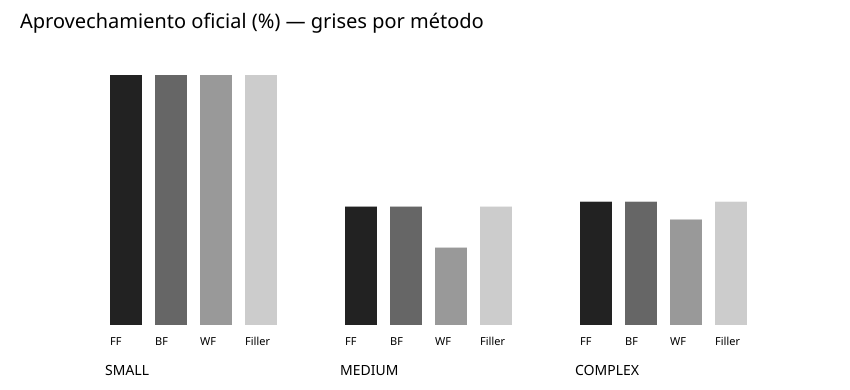

In [26]:
# Construimos un SVG de barras usando solo texto y formas vectoriales.
def bar_chart(rows, metric, title):
    # Definimos tamaño fijo para que el gráfico sea legible en Colab.
    width, height = 850, 390
    # Iniciamos el lienzo blanco.
    parts = [f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" height="{height}">', '<rect width="100%" height="100%" fill="white"/>']
    # Rotulamos el indicador.
    parts.append(f'<text x="20" y="28" font-family="sans-serif" font-size="20">{title}</text>')
    # Fijamos el orden de leyenda.
    methods = ["FF", "BF", "WF", "Filler"]
    # Usamos únicamente grises.
    shades = ["#222222", "#666666", "#999999", "#cccccc"]
    # Usamos una escala común para comparar los tres fixtures.
    maximum = max(float(row[metric]) for row in rows)
    # Creamos un grupo por fixture.
    for group_index, case in enumerate(CASES):
        # Buscamos valor real de cada método.
        values = [float(next(row[metric] for row in rows if row["case"] == case and row["method"] == method)) for method in methods]
        # Dibujamos una barra por método.
        for method_index, value in enumerate(values):
            # Calculamos la posición horizontal.
            x = 110 + group_index * 235 + method_index * 45
            # Escalamos todas las barras con el mismo máximo global.
            bar_height = value * (250 / maximum) if maximum else 0
            # Dibujamos barra gris.
            parts.append(f'<rect x="{x}" y="{325-bar_height:.1f}" width="32" height="{bar_height:.1f}" fill="{shades[method_index]}"/>')
            # Añadimos etiqueta del método.
            parts.append(f'<text x="{x}" y="345" font-family="sans-serif" font-size="11">{methods[method_index]}</text>')
        # Rotulamos fixture.
        parts.append(f'<text x="{105+group_index*235}" y="375" font-family="sans-serif" font-size="14">{case.replace("EXP-", "").replace("-001", "")}</text>')
    # Cerramos el documento SVG.
    parts.append('</svg>')
    # Devolvemos el vector listo para guardar en la salida.
    return "".join(parts)
# Graficamos la métrica oficial.
utilization_svg = bar_chart(consolidated, "utilization_pct", "Aprovechamiento oficial (%) — grises por método")
# El generador del notebook guarda SVG como salida renderizable.
print(utilization_svg)

**Interpretación:** Los datos muestran igualdad de FF/BF/Filler en COMPLEX; MEDIUM diferencia merma, pero no utilización entre esos tres métodos.

## Gráfico de fuentes utilizadas

Ejecuta el paso experimental y muestra su salida guardada.

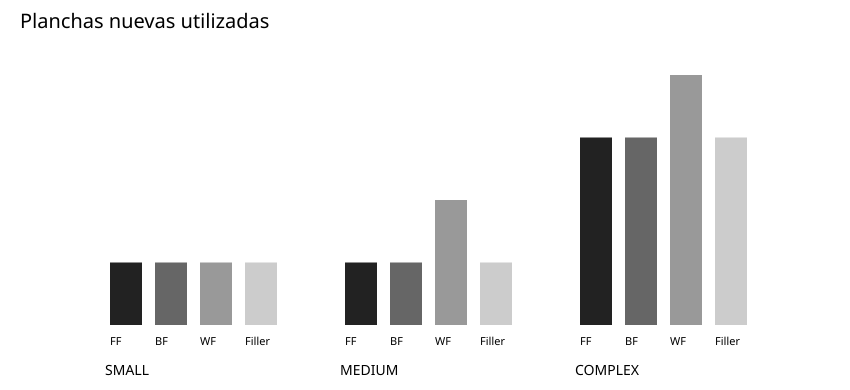

In [27]:
# Creamos otro SVG de barras con los conteos de planchas.
def stock_chart(rows):
    # Reutilizamos el mismo motor vectorial monocromo.
    return bar_chart(rows, "sheets_used", "Planchas nuevas utilizadas")
# Generamos el gráfico de stock de planchas.
sheets_svg = stock_chart(consolidated)
# Embebemos el vector como salida ejecutada.
print(sheets_svg)

**Interpretación:** WF requiere dos planchas en MEDIUM frente a una y cuatro en COMPLEX frente a tres para FF, BF y Filler.

## Gráfico de tiempo

Ejecuta el paso experimental y muestra su salida guardada.

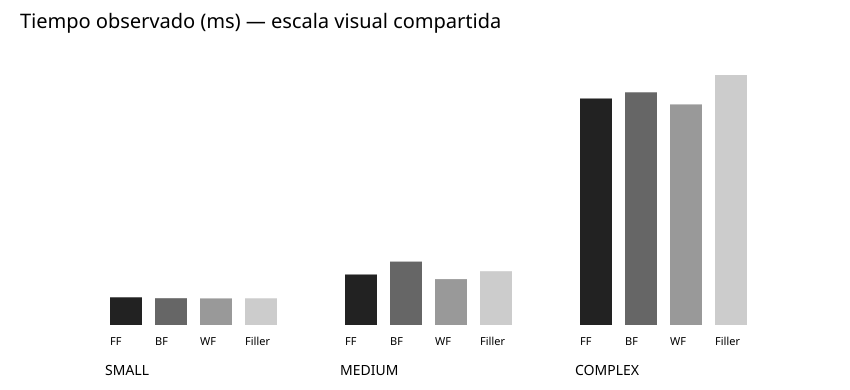

In [28]:
# Construimos el gráfico con tiempos CSV.
runtime_svg = bar_chart(consolidated, "runtime_ms", "Tiempo observado (ms) — escala visual compartida")
# Guardamos el SVG como salida del notebook ejecutado.
print(runtime_svg)

**Interpretación:** En la corrida registrada Filler tarda cerca de 21 ms en MEDIUM y 99 ms en COMPLEX; compare valores solo en el mismo entorno.

## Comportamiento específico Filler

Ejecuta el paso experimental y muestra su salida guardada.

In [29]:
# Recorremos todos los intentos de Filler del último caso.
for attempt in complex_trace.attempts:
    # Filtramos rechazos temporales y colocaciones.
    if attempt["decision"] == "skip_temporarily" or attempt["fits"]:
        # Mostramos detalle de decisión.
        print(attempt["piece_id"], attempt["area_mm2"], attempt["source"], attempt["material_id"], attempt["decision"], attempt["rotation_deg"], attempt["x_mm"], attempt["y_mm"])
# Reportamos el orden que terminó colocándose.
print("orden efectivo:", complex_trace.processing_order)
# Resumimos cuántas unidades entraron en cada objeto.
print("unidades por fuente:", complex_trace.pieces_per_source)
# Cerramos con diagnósticos.
print("cambios:", complex_trace.source_switches, "saltos:", complex_trace.skipped_piece_attempts, "rellenos tras skip:", complex_trace.successful_fill_after_skip)

1 27.00 RETAZO 1 place 0 1 1
1 27.00 RETAZO 1 place 0 1 5
1 27.00 RETAZO 1 skip_temporarily None None None
1 27.00 RETAZO 1 skip_temporarily None None None
1 27.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
4 18.00 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
3 12.57 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
2 12.00 RETAZO 1 skip_temporarily None None None
1 27.00 RETAZO 2 place 55 1 1
1 27.00 RETAZO 2 skip_temporarily None None None
1 27.00 RETAZO 2 skip_temporar

**Interpretación:** La traza completa está guardada en JSON; aquí se muestran intentos que explican el avance de la fuente activa.

## Observaciones experimentales

Ejecuta el paso experimental y muestra su salida guardada.

In [30]:
# Recorremos los tres experimentos en su orden oficial.
for case in CASES:
    # Filtramos los cuatro métodos para el caso.
    rows = [row for row in consolidated if row["case"] == case]
    # Comprobamos si la cobertura difiere.
    placed = {row["placed_units"] for row in rows}
    # Preparamos aprovechamientos medidos.
    utilization = {row["method"]: row["utilization_pct"] for row in rows}
    # Resumimos cobertura y eficiencia.
    print(case, "cobertura única:", len(placed) == 1, "aprovechamiento:", utilization)
# Registramos el control determinista observado.
print("Observación: Filler fue determinista en las tres repeticiones de cada fixture.")
# Declaramos el alcance del resultado.
print("Limitación: solo hay tres fixtures congelados y el tiempo local no se extrapola a producción.")

EXP-SMALL-001 cobertura única: True aprovechamiento: {'FF': '60.000', 'BF': '60.000', 'WF': '60.000', 'Filler': '60.000'}
EXP-MEDIUM-001 cobertura única: True aprovechamiento: {'FF': '28.413', 'BF': '28.413', 'WF': '18.584', 'Filler': '28.413'}
EXP-COMPLEX-001 cobertura única: True aprovechamiento: {'FF': '29.598', 'BF': '29.598', 'WF': '25.309', 'Filler': '29.598'}
Observación: Filler fue determinista en las tres repeticiones de cada fixture.
Limitación: solo hay tres fixtures congelados y el tiempo local no se extrapola a producción.


**Interpretación:** Los datos no sostienen una mejora general de Filler. Filler es distinto por política y por sus intentos, pero coincide con FF en estos fixtures; WF consume más planchas en MEDIUM y COMPLEX. El resultado debe validarse de nuevo en Colab.